# Feature engineering — riesgo por segmento de calle (Eje 2)

| | |
|---|---|
| **Entrada** | `clean/denuncias_eje2_clean.parquet` (EDA), grafo peatonal y POIs de OSM (`graph/`), puntos de acceso (`backend/data/geo`) |
| **Grano de salida** | una fila = un **segmento de calle × año objetivo** |
| **Regla de oro** | las features del año *Y* usan **solo eventos de años < Y**; el objetivo son los eventos del año *Y*. El **test (enero–agosto de 2024) no se toca** |
| **Salida** | `features/panel_train.parquet` (objetivos 2019–2022), `features/panel_valid.parquet` (objetivo 2023) y tablas de apoyo |

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = Path.cwd().resolve().parents[2]            # deliveries/week12
sys.path.insert(0, str(RAIZ / "code" / "eje2"))
import eje2_common as C, eje2_features as FE

BASE  = RAIZ / "data_processed" / "eje2"
CLEAN, GRAPH, FEAT = BASE / "clean", BASE / "graph", BASE / "features"
FIGS  = RAIZ / "docs" / "images"
GEO   = RAIZ.parents[1] / "backend" / "data" / "geo"
FEAT.mkdir(exist_ok=True); FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
AZUL, ROJO = "#1f4fd8", "#d64545"
def guardar_fig(n): plt.savefig(FIGS / n, bbox_inches="tight"); plt.show()

## 1. Puntos de acceso — ¿qué vamos a hacer?

Reunir en una sola tabla los lugares desde donde alguien empieza a caminar: **estaciones del Metro L1**, **estaciones del
Metropolitano (troncal)**, y **paraderos de corredores y de alimentadores**. Se leen de `backend/data/geo` (los mismos datos
que usa la app). Los paraderos de alimentadores traen `precision` y `confianza` de su coordenada: se conservan porque
alimentan la etiqueta de confianza del índice por punto de acceso.

In [2]:
fuentes = {"metro_l1": ("puntos_metro_l1.geojson", "estacion"), "troncal": ("puntos_troncal.geojson", "estacion"),
           "corredor": ("paradas_corredores.geojson", "paradero"), "alimentador": ("paradas_alimentadores.geojson", "paradero")}
parts = []
for tipo, (f, ncol) in fuentes.items():
    g = gpd.read_file(GEO / f).to_crs(4326)
    parts.append(pd.DataFrame({
        "tipo": tipo, "nombre": g[ncol].astype(str).values, "ruta": g["ruta"].astype(str).values if "ruta" in g else g["servicio"].astype(str).values if "servicio" in g else "",
        "precision_coord": g["precision"].values if "precision" in g else None,
        "confianza_coord": g["confianza"].values if "confianza" in g else None,
        "lon": g.geometry.x.values, "lat": g.geometry.y.values}))
acc = pd.concat(parts, ignore_index=True)
acc["acceso_id"] = acc.tipo + "_" + acc.index.astype(str).str.zfill(4)
acc = gpd.GeoDataFrame(acc, geometry=gpd.points_from_xy(acc.lon, acc.lat), crs=4326).to_crs(FE.CRS_M)
print(acc.tipo.value_counts().to_dict())
print("ubicaciones distintas (redondeo 5 decimales):", acc[["lon","lat"]].round(5).drop_duplicates().shape[0], "de", len(acc))
print("precisión de coordenada (alimentadores):", acc[acc.tipo=="alimentador"].precision_coord.value_counts().to_dict())
print("confianza:", acc[acc.tipo=="alimentador"].confianza_coord.value_counts().to_dict())
acc.drop(columns="geometry").to_parquet(FEAT / "puntos_acceso.parquet", index=False)

{'corredor': 993, 'alimentador': 712, 'troncal': 44, 'metro_l1': 26}
ubicaciones distintas (redondeo 5 decimales): 1494 de 1775
precisión de coordenada (alimentadores): {'aproximada': 404, 'exacta': 308}
confianza: {'media': 325, 'baja': 275, 'alta': 112}


### Qué encontramos (puntos de acceso)

- **1 775 puntos de acceso**: 26 estaciones del Metro L1, 44 del Metropolitano, 993 paraderos de corredores y 712 de alimentadores.
- Solo hay **1 494 ubicaciones distintas**: muchos paraderos comparten coordenada entre rutas.
- En alimentadores, la coordenada es **aproximada en 404 de 712 paraderos (57 %)** y exacta en 308. La confianza del método es alta en 112, media en 325 y **baja en 275 (39 %)**.

**Decisión:** conservar todos los puntos. La precisión de la coordenada baja la etiqueta de confianza del índice (sección 8 del modelo): un paradero ubicado de forma aproximada puede mostrar el entorno de otra esquina.

## 2. Grafo peatonal y zona de ~10 minutos — ¿qué vamos a hacer?

1. Cargar el grafo de calles descargado **offline** (`scripts/02_descarga_osm.py`; osmnx no se usa en producción).
2. Convertir las aristas dirigidas de OSM en **segmentos físicos únicos** (una calle = una fila).
3. Para cada punto de acceso, calcular con **Dijkstra con límite de 800 m** qué segmentos quedan a ~10 min *caminando por la red*
   (no en línea recta). Así una calle al otro lado de una autopista no cuenta como "cercana".

In [3]:
aristas = gpd.read_parquet(GRAPH / "aristas.parquet"); nodos = gpd.read_parquet(GRAPH / "nodos.parquet")
segs = FE.preparar_segmentos(aristas)
print(f"{len(aristas):,} aristas dirigidas -> {len(segs):,} segmentos físicos · {len(nodos):,} nodos")
print(segs.via.value_counts().to_dict())
memb, snap = FE.membresia_accesos(segs, nodos, acc)
print(f"membresía acceso-segmento: {len(memb):,} filas")
print("distancia (m) del punto de acceso al nodo más cercano:"); print(snap.describe(percentiles=[.5, .9, .99]).round(0).to_string())
zona = memb.groupby("seg_id").agg(dist_acceso_m=("dist_m", "min"), n_accesos=("acceso_id", "nunique"))
segz = segs.merge(zona, left_on="seg_id", right_index=True)
tipo_cerca = memb.merge(acc[["acceso_id", "tipo"]], on="acceso_id").sort_values("dist_m").drop_duplicates("seg_id").set_index("seg_id").tipo
segz["tipo_acceso_cercano"] = segz.seg_id.map(tipo_cerca)
print(f"\nSegmentos en la zona: {len(segz):,} de {len(segs):,} · longitud total {segz.length_m.sum()/1000:,.0f} km")
print(segz.n_accesos.describe().round(1).to_string())
por_acc = memb.groupby("acceso_id").size().rename("n_seg").to_frame().join(acc.set_index("acceso_id").tipo)
print("\nSegmentos por punto de acceso (mediana) según tipo:"); print(por_acc.groupby("tipo").n_seg.median().to_string())
segz.to_parquet(FEAT / "segmentos_zona.parquet", index=False); memb.to_parquet(FEAT / "acceso_segmentos.parquet", index=False)
snap.to_frame().to_parquet(FEAT / "acceso_snap.parquet")

377,078 aristas dirigidas -> 188,893 segmentos físicos · 131,835 nodos
{'residencial': 71323, 'peatonal': 71169, 'arterial': 34421, 'servicio': 11378, 'otra': 602}


membresía acceso-segmento: 1,196,270 filas
distancia (m) del punto de acceso al nodo más cercano:
count    1775.0
mean       19.0
std        11.0
min         0.0
50%        17.0
90%        34.0
99%        52.0
max        85.0



Segmentos en la zona: 146,607 de 188,893 · longitud total 7,012 km
count    146607.0
mean          8.2
std           8.5
min           1.0
25%           2.0
50%           5.0
75%          11.0
max          60.0

Segmentos por punto de acceso (mediana) según tipo:
tipo
alimentador    528.0
corredor       721.0
metro_l1       754.5
troncal        769.0


### Qué encontramos (grafo y zona de 10 minutos)

- El grafo de OSM tiene 377 078 aristas dirigidas = **188 893 segmentos físicos** y 131 835 nodos. Por tipo de vía: 71 323 residenciales, 71 169 peatonales (veredas, pasajes, escaleras), 34 421 arteriales, 11 378 de servicio y 602 otras.
- Cada punto de acceso queda a **17 m (mediana)** del nodo de la red más cercano y como máximo a 85 m: no hay puntos de acceso perdidos en un lugar sin calles.
- Las zonas de ~10 min (800 m caminando) cubren **146 607 segmentos (78 %), 7 012 km de calle**. Un segmento pertenece en promedio a 8,2 zonas (mediana 5, máximo 60): los entornos de corredores y alimentadores se **solapan mucho**.
- Segmentos por punto de acceso (mediana): 528 en alimentadores, 721 en corredores, 754 en Metro L1 y 769 en troncales.

**Decisión:** modelar por segmento (no por estación) y calcular el índice de cada punto de acceso a partir de sus segmentos, ya que los entornos se comparten.

## 3. Eventos → segmentos — ¿qué vamos a hacer?

Cada denuncia (ya filtrada en el EDA: hecho callejero, coordenada real, no apilada) se asigna al **segmento más cercano a ≤ 40 m**
(`sjoin_nearest` en metros, UTM 18S). Lo que cae lejos de toda calle de la zona queda sin asignar y se cuenta. También se
asigna a cada segmento su **comisaría** (la del evento asignado más cercano), porque la cobertura de coordenadas depende de ella.

In [4]:
ev = pd.read_parquet(CLEAN / "denuncias_eje2_clean.parquet")
print(f"Eventos limpios: {len(ev):,} (train {int((ev.split=='train').sum()):,} · valid {int((ev.split=='valid').sum()):,})")
asig = FE.asignar_eventos(ev, segz, max_m=40)
print(f"Asignados a un segmento de la zona (<= 40 m): {len(asig):,} ({len(asig)/len(ev):.1%})")
print(asig.dist_evento_m.describe(percentiles=[.5, .9, .99]).round(1).to_string())
evs = ev.merge(asig, on="id_dgc")
seg_com = FE.comisaria_por_segmento(evs, segz)
print("\nEventos por grupo en la zona:"); print(evs.grupo.value_counts().to_dict())
print("Comisarías distintas en la zona:", seg_com.nunique())
evs.to_parquet(FEAT / "eventos_segmento.parquet", index=False); seg_com.to_frame().to_parquet(FEAT / "segmento_comisaria.parquet")

Eventos limpios: 495,374 (train 364,647 · valid 130,727)


Asignados a un segmento de la zona (<= 40 m): 237,498 (47.9%)
count    237498.0
mean          7.5
std           8.5
min           0.0
50%           4.1
90%          19.9
99%          36.5
max          40.0



Eventos por grupo en la zona:
{'hurto': 134985, 'robo_persona': 73853, 'violencia_fisica': 15479, 'agresion_sexual': 9620, 'acoso': 3561}
Comisarías distintas en la zona: 92


### Qué encontramos (eventos a segmentos)

- De 495 374 eventos limpios, **237 498 (47,9 %)** caen a ≤ 40 m de un segmento de alguna zona: distancia mediana 4,1 m, p90 19,9 m, p99 36,5 m. El otro 52 % ocurrió fuera de los entornos de 10 min de cualquier acceso (o lejos de una calle) y no entra a este modelo.
- Eventos en la zona por grupo: hurto 134 985, robo a la persona 73 853, violencia física 15 479, agresión sexual 9 620 y **acoso 3 561**.
- Se identifican 92 comisarías en la zona.

**Decisión:** el acoso (3 561 eventos repartidos en 146 607 segmentos) es demasiado escaso para modelarse solo; se agrupa con agresión sexual y violencia física en el objetivo `y_per` ("persona"). Robo y hurto forman `y_pat`.

## 4. Contexto de la calle: POIs y vecindad — ¿qué vamos a hacer?

- **Puntos de interés de OSM** (comercio, bares, bancos, colegios, salud, mercados, restaurantes, parques, paraderos de bus)
  a ≤ 50 m de cada segmento. Describen **uso del suelo y flujo de gente**; no describen ingreso ni nivel socioeconómico del barrio.
- **Matriz de vecindad**: dos segmentos son vecinos si comparten una esquina. Sirve para el riesgo de las calles contiguas (1 y 2 saltos).

In [5]:
pois = gpd.read_parquet(GRAPH / "pois.parquet")
poi = FE.conteo_pois(pois, segz)
print(f"{len(pois):,} POIs en la zona · " + str(pois.cat.value_counts().to_dict()))
print(f"Segmentos con al menos un POI a <= 50 m: {(poi.sum(axis=1) > 0).mean():.1%}")
S = FE.matriz_vecindad(segz)
grado = np.asarray(S.sum(axis=1)).ravel()
print(f"Vecindad: {S.nnz:,} pares · vecinos por segmento: mediana {np.median(grado):.0f}, máx {grado.max()}")
poi.to_parquet(FEAT / "poi_segmento.parquet")

32,100 POIs en la zona · {'comercio': 10097, 'educacion': 6699, 'restaurante': 4551, 'parque': 3827, 'paradero_bus': 2733, 'salud': 2313, 'banco': 945, 'mercado': 560, 'bar_ocio': 375}
Segmentos con al menos un POI a <= 50 m: 11.3%
Vecindad: 634,786 pares · vecinos por segmento: mediana 4, máx 10.0


### Qué encontramos (contexto de la calle)

- Hay 32 100 POIs en la zona (comercio 10 097, educación 6 699, restaurantes 4 551, parques 3 827, paraderos de bus 2 733, salud 2 313, bancos 945, mercados 560, bares y ocio 375).
- Solo el **11,3 % de los segmentos** tiene un POI a ≤ 50 m: OSM en Lima tiene poca cobertura de comercio informal. Es probable que los POIs aporten poco; la ablación del modelo lo confirmará.
- Vecindad: 634 786 pares de segmentos contiguos, mediana 4 vecinos por segmento (máximo 10).

**Decisión:** conservar los POIs como candidatos y quedarse con ellos solo si mejoran la validación.

## 5. Panel segmento × año — ¿qué vamos a hacer?

Para cada año objetivo *Y* ∈ 2019–2023 y cada segmento de la zona se calculan:

- **Features (solo años < Y):** tasa histórica de eventos por mes válido, tasa del año anterior, tasa con **decaimiento temporal**
  (vida media 1,5 años), tasas por tipo (patrimonio vs. persona), fracción nocturna, tasa de las calles vecinas a 1 y 2 saltos,
  tipo de vía, largo y POIs.
- **Corrección de cobertura (del EDA):** cada evento pesa `1 / cobertura(comisaría, año)` con tope 4, y se descartan los meses con
  < 50 % de coordenada utilizable. La exposición del Poisson es `meses_válidos/12 × cobertura(comisaría, Y)`.
- **Objetivos (año Y):** conteos observados `y_total`, `y_noche`, `y_dia`, `y_pat` (robo + hurto) y `y_per` (acoso + agresión sexual
  + violencia física).

Train = objetivos 2019–2022; valid = objetivo 2023.

In [6]:
cob = pd.read_csv(CLEAN / "cobertura_comisaria_anio.csv")
bajos = set(pd.read_csv(CLEAN / "meses_baja_cobertura.csv").mes)
print("meses de baja cobertura excluidos:", sorted(bajos))
panel = FE.construir_panel(evs, segz, seg_com, S, cob, bajos, anios_obj=range(2019, 2024))
panel = panel.merge(poi.reset_index(), on="seg_id", how="left")
panel["prior_vec"] = panel.vec1 / panel.n_vec1.clip(lower=1)
print(f"Panel: {len(panel):,} filas = {panel.seg_id.nunique():,} segmentos x {panel.anio_obj.nunique()} años · {panel.shape[1]} columnas")
res = panel.groupby("anio_obj").agg(y_total=("y_total", "sum"), seg_con_evento=("y_total", lambda s: (s > 0).mean()), expo_media=("expo", "mean"))
print(res.round(3).to_string())

meses de baja cobertura excluidos: ['2019-09', '2019-10', '2019-11']


Panel: 733,035 filas = 146,607 segmentos x 5 años · 31 columnas
          y_total  seg_con_evento  expo_media
anio_obj                                     
2019        31583           0.079       0.603
2020        20769           0.062       0.758
2021        27511           0.076       0.765
2022        38251           0.093       0.821
2023        65919           0.128       0.850


**Lectura (panel):** 733 035 filas (146 607 segmentos × 5 años) con features de solo pasado y objetivos del año; entre 6 % y 13 % de los segmentos tiene algún evento por año.

**Siguiente paso:** comprobar que las features no ven el futuro y medir qué tan relacionadas están con los eventos del año.

Año objetivo 2019: eventos del pasado (solo 2018) = 50491 · eventos 2018 asignados = 50491 (menos los de meses de baja cobertura)

Correlación de Spearman con y_total (años >= 2020):
tasa_all     0.432
tasa_prev    0.414
decay        0.433
vec1         0.218


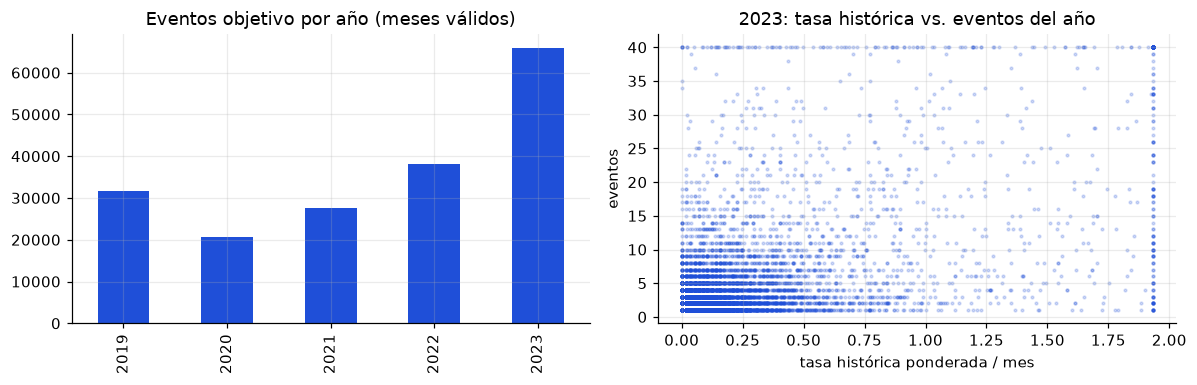

In [7]:
# Comprobación anti-fuga: las features de Y solo ven años < Y
y19 = panel[panel.anio_obj == 2019]
print("Año objetivo 2019: eventos del pasado (solo 2018) =", int(y19.n_eventos_pasado.sum()), "· eventos 2018 asignados =", int((evs.anio == 2018).sum()),
      "(menos los de meses de baja cobertura)")
rho = panel[panel.anio_obj >= 2020][["tasa_all", "tasa_prev", "decay", "vec1", "y_total"]].corr(method="spearman").y_total.drop("y_total")
print("\nCorrelación de Spearman con y_total (años >= 2020):"); print(rho.round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
panel.groupby("anio_obj").y_total.sum().plot.bar(ax=ax[0], color=AZUL); ax[0].set(title="Eventos objetivo por año (meses válidos)", xlabel="")
s = panel[(panel.anio_obj == 2023) & (panel.y_total > 0)]
ax[1].scatter(s.tasa_all.clip(upper=s.tasa_all.quantile(.99)), s.y_total.clip(upper=s.y_total.quantile(.99)), s=3, alpha=.2, color=AZUL)
ax[1].set(title="2023: tasa histórica vs. eventos del año", xlabel="tasa histórica ponderada / mes", ylabel="eventos")
plt.tight_layout(); guardar_fig("fe_panel_objetivo.png")

### Qué encontramos (panel)

- **733 035 filas** = 146 607 segmentos × 5 años objetivo (2019–2023). Train 586 428 (2019–2022) y valid 146 607 (2023).
- Es un problema **muy disperso**: solo entre 6,2 % y 12,8 % de los segmentos tiene al menos un evento en un año. Eventos objetivo por año: 31 583 (2019), 20 769 (2020, pandemia), 27 511, 38 251 y 65 919 (2023).
- La exposición media (meses válidos × cobertura) es 0,60 en 2019, 0,76–0,77 en 2020–2021, 0,82 en 2022 y 0,85 en 2023.
- Correlación de Spearman con los eventos del año: decaimiento temporal 0,433, tasa histórica 0,432, tasa del año anterior 0,414 y tasa de vecinos 0,218. **El historial del propio segmento es la señal más fuerte**; los vecinos aportan menos.
- Comprobación anti-fuga: para el año objetivo 2019 los eventos del pasado son 50 491, exactamente los de 2018.
- `frac_noche` tiene 83,0 % de nulos (segmentos sin eventos previos); los árboles lo manejan y el GLM recibe una bandera.

**Decisión:** modelar conteos con **Poisson y offset de exposición**, y comparar contra el historial suavizado como línea base seria.

## 6. Guardado y diccionario de features

In [8]:
panel[panel.anio_obj <= 2022].to_parquet(FEAT / "panel_train.parquet", index=False)
panel[panel.anio_obj == 2023].to_parquet(FEAT / "panel_valid.parquet", index=False)
dic = pd.DataFrame({"columna": panel.columns, "dtype": panel.dtypes.astype(str).values, "nulos_%": (panel.isna().mean() * 100).round(1).values})
dic.to_csv(FEAT / "diccionario_features.csv", index=False)
print("train:", int((panel.anio_obj <= 2022).sum()), "· valid:", int((panel.anio_obj == 2023).sum()))
print(dic[dic["nulos_%"] > 0].to_string(index=False))

train: 586428 · valid: 146607
   columna   dtype  nulos_%
frac_noche float64     83.0


### Conclusiones

1. El Eje 2 se modela por **segmento de calle** (146 607 segmentos, 7 012 km) y los índices de estaciones y paraderos salen de sus entornos de 800 m caminando, que se solapan bastante.
2. Solo 47,9 % de los eventos limpios cae en esas zonas; el modelo describe el entorno de las estaciones y paraderos, no toda Lima.
3. El problema es disperso (6–13 % de segmentos con evento por año): se usa Poisson con offset y suavizado.
4. El historial propio del segmento es la mejor señal (Spearman ≈ 0,43); los vecinos y POIs se evalúan en el modelo.
5. Las coordenadas aproximadas de los paraderos de alimentadores (57 %) bajan la confianza del índice.
6. El test (enero–agosto de 2024) no se tocó; sus features se generan en la evaluación final con las mismas funciones (`eje2_features.py`).